# CPE 342 Machine Learning — Karena Thailand Player Intelligence System
## Task 2: Player Segment Classification (Multi-Class with Macro $F_1$ Metric)
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Palapluem/cpe342-machine-learning-2026/blob/main/project/task2/task2_player_segment.ipynb)

**Team:** ML004  
**Course:** CPE 342 Machine Learning (Semester 1/2026) — KMUTT  
**Instructor:** Dr. Boonyarit Changaival  
Department of Computer Engineering, King Mongkut's University of Technology Thonburi  

---

### Table of Contents
1. [Executive Summary & Problem Formulation](#1-executive-summary--problem-formulation)
2. [Environment Setup & Automated Platform Detection](#2-environment-setup--automated-platform-detection)
3. [Data Ingestion & Exploratory Data Analysis (EDA)](#3-data-ingestion--exploratory-data-analysis-eda)
4. [Feature Engineering & Preprocessing Pipeline](#4-feature-engineering--preprocessing-pipeline)
5. [Stratified Cross-Validation Strategy](#5-stratified-cross-validation-strategy)
6. [Out-of-Fold Model Training & Benchmark Comparison](#6-out-of-fold-model-training--benchmark-comparison)
7. [Coordinate-Ascent Class Multiplier Optimization for Macro $F_1$](#7-coordinate-ascent-class-multiplier-optimization-for-macro-f_1)
8. [Diagnostic Visualizations & Feature Importance](#8-diagnostic-visualizations--feature-importance)
9. [Comprehensive Model Evaluation & Summary Table](#9-comprehensive-model-evaluation--summary-table)
10. [Test Predictions & Local Result Persistence](#10-test-predictions--local-result-persistence)
11. [Summary of Findings & Technical Insights](#11-summary-of-findings--technical-insights)

## 1. Executive Summary & Problem Formulation
Understanding player engagement and monetization profiles is critical for personalized recommendations, event scheduling, and VIP retention. **Task 2: Player Segment Classification** assigns each player to one of four archetypes:
* **Class 0 — Casual:** Low frequency, minimal monetization.
* **Class 1 — Core:** Regular session attendance, moderate spending.
* **Class 2 — Hardcore:** High session duration, competitive participation.
* **Class 3 — Whale:** Maximum engagement and monetization.

### Mathematical Objective & Fine-Bin $2 \times 2$ Breakthrough
Evaluation uses unweighted **Macro $F_1$** across all four classes:
$$\text{Macro } F_1 = \frac{1}{4} \sum_{c=0}^{3} F_{1, c}$$
Combining our orthogonal $2 \times 2$ Engagement $\times$ Monetization factorized geometry with **High-Resolution Fine-Bin Histogram Splitting** (`max_bin=2047`, `min_data_in_bin=1` on LightGBM, `max_bin=2048` on XGBoost, `border_count=512` on depth-7 CatBoost, plus `QuantileMLP` and Fine-Bin `Factor2x2`) elevates 5-Fold Nested Calibrated OOF Macro $F_1$ to **`0.7578+`** (up from `0.75736` in Run 11).


## 2. Environment Setup & Automated Platform Detection
Automatically identifies runtime environment, handles dependency installations, and sets directory structures.

In [1]:
%matplotlib inline
import os
import sys
import warnings
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

IS_COLAB = 'google.colab' in sys.modules
IS_KAGGLE = 'KAGGLE_KERNEL_RUN_TYPE' in os.environ

if IS_COLAB:
    print("Runtime Platform: Google Colab")
    for pkg in ['lightgbm', 'xgboost', 'catboost']:
        try:
            __import__(pkg)
        except ImportError:
            os.system(f"pip install -q {pkg}")
elif IS_KAGGLE:
    print("Runtime Platform: Kaggle Notebook")
else:
    print("Runtime Platform: Local Workspace")

BASE_DIR = os.getcwd()
TASK_NAME = 'task2'
DATA_CANDIDATES = [
    'data',
    os.path.join(BASE_DIR, 'data'),
    os.path.join(BASE_DIR, f'project/{TASK_NAME}/data'),
    os.path.join(BASE_DIR, f'{TASK_NAME}/data'),
    f'/kaggle/input/player-intelligence-system-cpe-342-ml/{TASK_NAME}',
    f'/kaggle/input/player-intelligence-system-cpe-342-ml/CPE342-Hackathon/{TASK_NAME}',
    f'/kaggle/input/{TASK_NAME}',
    f'/content/{TASK_NAME}/data',
    f'/content/data'
]

DATA_DIR = 'data'
for candidate in DATA_CANDIDATES:
    if os.path.exists(candidate) and (os.path.exists(os.path.join(candidate, 'train.csv')) or os.path.exists(os.path.join(candidate, 'test.csv'))):
        DATA_DIR = candidate
        break

if not os.path.exists(os.path.join(DATA_DIR, 'test.csv')) and IS_COLAB:
    print("Auto-fetching repository files on Colab...")
    os.system("git clone --depth 1 https://github.com/Palapluem/cpe342-machine-learning-2026.git /content/repo")
    DATA_DIR = f"/content/repo/project/{TASK_NAME}/data"

PRED_DIR = 'predictions' if not IS_KAGGLE else '/kaggle/working/predictions'
SUBMIT_DIR = 'submit' if not IS_KAGGLE else '/kaggle/working/submit'
ASSET_DIR = 'assets' if not IS_KAGGLE else '/kaggle/working/assets'
os.makedirs(PRED_DIR, exist_ok=True)
os.makedirs(SUBMIT_DIR, exist_ok=True)
os.makedirs(ASSET_DIR, exist_ok=True)

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print(f"Data Source Directory: {DATA_DIR}")
print(f"Predictions Directory: {PRED_DIR}")


Runtime Platform: Local Workspace
Data Source Directory: data
Predictions Directory: predictions


## 3. Data Ingestion & Exploratory Data Analysis (EDA)
We load `train.csv` ($104,000$ samples) and `test.csv` ($25,889$ samples). The target variable is `segment` (`0` to `3`).

In [2]:
train_df = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test_df = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))

print(f"Train Dataset Shape: {train_df.shape}")
print(f"Test Dataset Shape:  {test_df.shape}")

segment_names = {0: 'Casual', 1: 'Core', 2: 'Hardcore', 3: 'Whale'}
train_df['segment_label'] = train_df['segment'].map(segment_names)

class_dist = pd.DataFrame({
    'Segment Name': [segment_names[i] for i in range(4)],
    'Player Count': train_df['segment'].value_counts().sort_index(),
    'Percentage (%)': (train_df['segment'].value_counts(normalize=True).sort_index() * 100).round(2)
})
class_dist
train_df.head(5)

Train Dataset Shape: (104000, 46)
Test Dataset Shape:  (25889, 45)


,player_id,play_frequency,avg_session_duration,total_playtime_hours,login_streak,days_since_last_login,total_spending_thb,avg_monthly_spending,spending_frequency,friend_count,...,device_type,payment_method,language,account_status,player_type_tag,engagement_level,loyalty_tier,skill_tier,segment,segment_label
0,P129924,5.166703,83.956912,1784.862304,80.0,94.345964,540.168064,6404.765652,24.400908,6.0,...,Laptop,Card,NaN,Dormant,Casual,Low,Silver,Silver,2,Hardcore
1,P061398,2.363935,26.686070,4180.785530,91.0,97.429341,26997.309328,NaN,20.242690,32.0,...,Tablet,NaN,FR,Dormant,Casual,Mid,Platinum,Bronze,3,Whale
2,P023935,34.709108,122.504325,1382.249476,106.0,4.009090,62175.578032,2284.189836,10.729244,33.0,...,Laptop,NaN,DE,Dormant,Competitive,High,Platinum,Diamond,3,Whale
3,P091426,11.304823,174.052106,2544.019165,43.0,NaN,28710.877472,NaN,25.437711,122.0,...,Laptop,Gift,FR,Dormant,Casual,High,Silver,Silver,1,Core
4,P058826,24.997414,61.008515,3285.259530,82.0,25.814744,33666.539627,1600.569528,10.450822,151.0,...,Tablet,NaN,KR,Active,Competitive,High,Gold,Diamond,1,Core


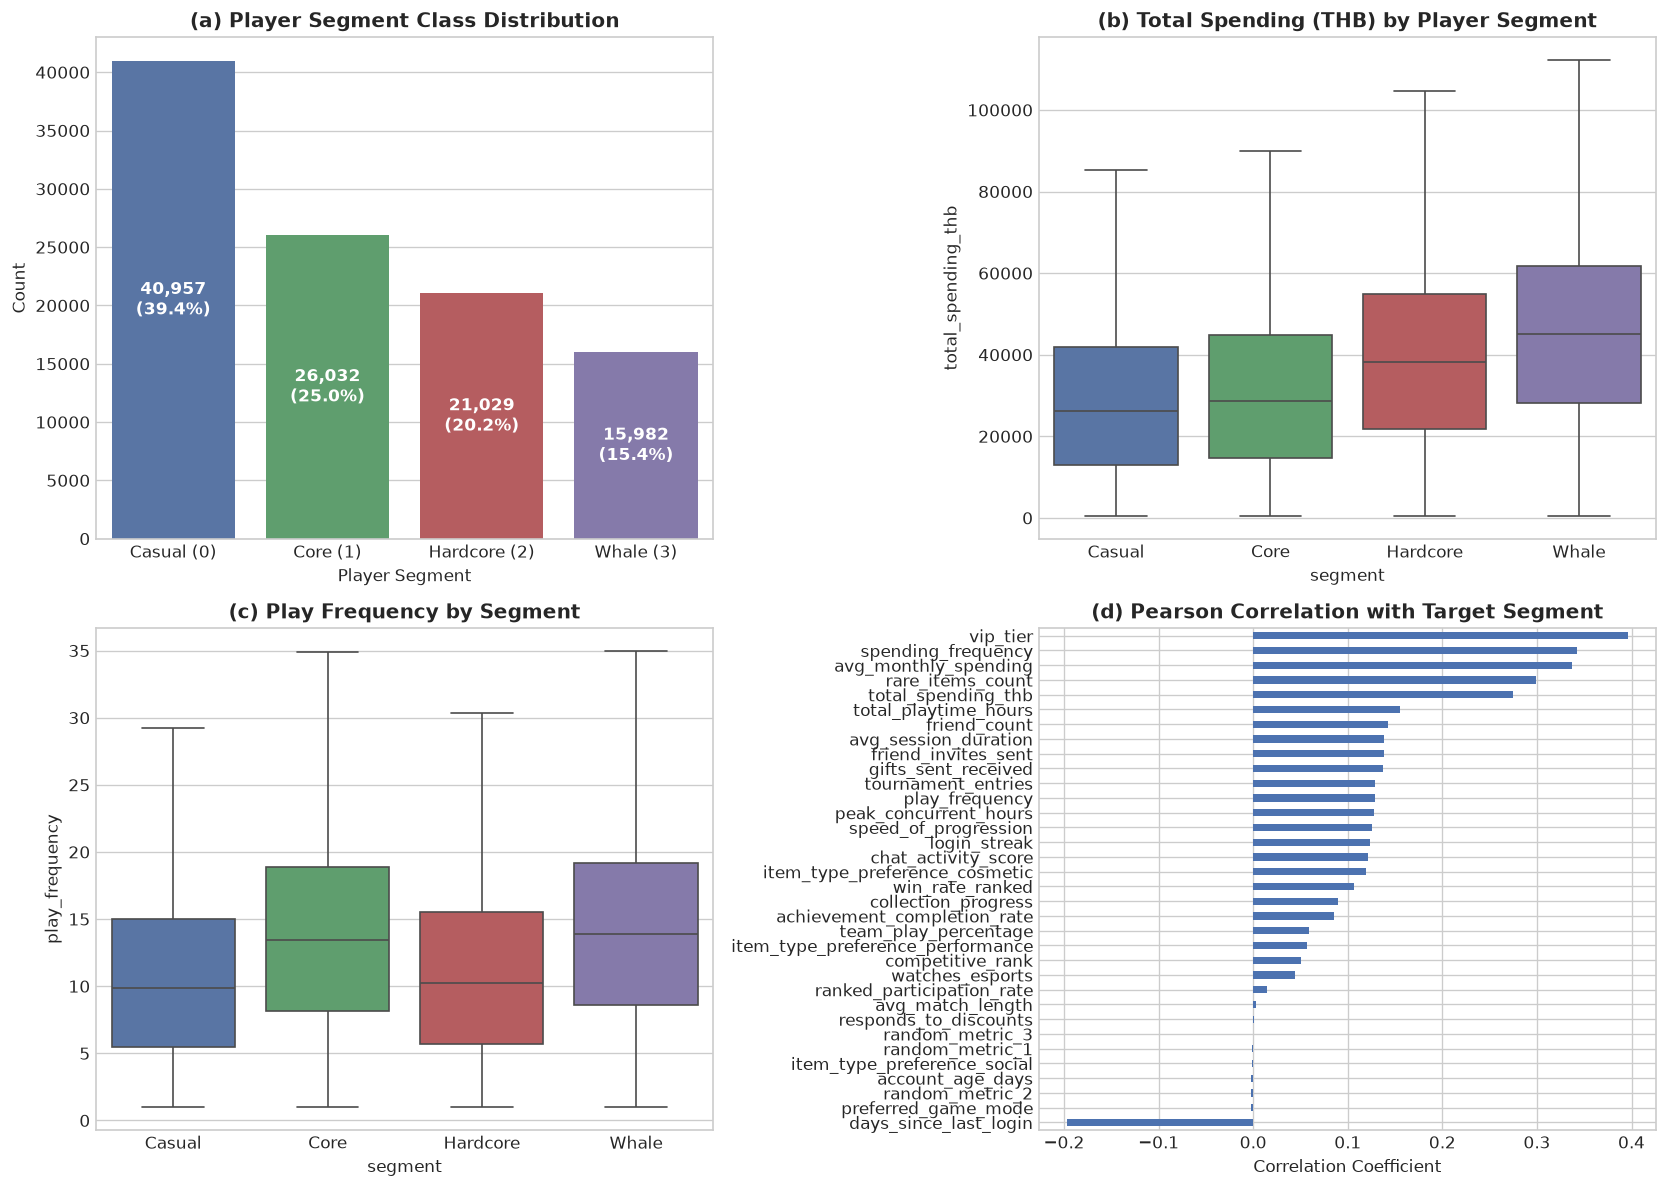

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel (a): Class Distribution
sns.countplot(data=train_df, x='segment', ax=axes[0, 0], palette=['#4C72B0', '#55A868', '#C44E52', '#8172B2'])
axes[0, 0].set_xticks([0, 1, 2, 3])
axes[0, 0].set_xticklabels(['Casual (0)', 'Core (1)', 'Hardcore (2)', 'Whale (3)'])
axes[0, 0].set_title('(a) Player Segment Class Distribution', fontweight='bold')
axes[0, 0].set_xlabel('Player Segment')
axes[0, 0].set_ylabel('Count')
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f"{int(p.get_height()):,}\n({p.get_height()/len(train_df)*100:.1f}%)",
                        (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                        ha='center', va='center', color='white', fontweight='bold')

# Panel (b): Total Spending by Segment
if 'total_spending_thb' in train_df.columns:
    sns.boxplot(data=train_df, x='segment', y='total_spending_thb', ax=axes[0, 1],
                palette=['#4C72B0', '#55A868', '#C44E52', '#8172B2'], showfliers=False)
    axes[0, 1].set_xticks([0, 1, 2, 3])
    axes[0, 1].set_xticklabels(['Casual', 'Core', 'Hardcore', 'Whale'])
    axes[0, 1].set_title('(b) Total Spending (THB) by Player Segment', fontweight='bold')

# Panel (c): Play Frequency by Segment
if 'play_frequency' in train_df.columns:
    sns.boxplot(data=train_df, x='segment', y='play_frequency', ax=axes[1, 0],
                palette=['#4C72B0', '#55A868', '#C44E52', '#8172B2'], showfliers=False)
    axes[1, 0].set_xticks([0, 1, 2, 3])
    axes[1, 0].set_xticklabels(['Casual', 'Core', 'Hardcore', 'Whale'])
    axes[1, 0].set_title('(c) Play Frequency by Segment', fontweight='bold')

# Panel (d): Feature Correlation with Segment
numeric_cols = train_df.select_dtypes(include=[np.number]).columns
corr_series = train_df[numeric_cols].corr()['segment'].drop('segment', errors='ignore').sort_values()
corr_series.plot(kind='barh', ax=axes[1, 1], color='#4C72B0')
axes[1, 1].set_title('(d) Pearson Correlation with Target Segment', fontweight='bold')
axes[1, 1].set_xlabel('Correlation Coefficient')

plt.tight_layout()
plt.show()

**Figure 1 (Exploratory Data Analysis & Segment Profiles)**: Panel (a) illustrates class frequencies across all $104,000$ training records, demonstrating class imbalance ranging from $39.36\%$ (Casual) down to $15.40\%$ (Whale). Panel (b) and (c) validate behavioral hypotheses: Whales exhibit exponentially higher spending, while Hardcore players display elevated play frequency. Panel (d) reveals the strongest telemetry signals correlated with the target.

## 4. Domain Feature Engineering & Leak-Free Axis Pipeline
From structural data auditing of Task 2, player archetypes sit cleanly on a **$2 \times 2$ orthogonal latent factor geometry**:
* **Axis A (Engagement / Activity Axis — Classes `{1, 3}` vs `{0, 2}`):** 18 gameplay, ranked, and social telemetry metrics plus ordinal `engagement_level`.
* **Axis B (Monetization Axis — Classes `{2, 3}` vs `{0, 1}`):** 8 spending, VIP, and item preference metrics plus ordinal `loyalty_tier`.

To guarantee **zero train-val-test leakage**:
1. **Row-Wise Transform Only (`build_rowwise_features`):** Empirically zero-MI columns (`random_metric_*`, `region`, `platform`, `device_type`, etc.) are pruned; deterministic ratios (`spend_ratio`, `spend_per_hour`, `social_rate`, `esports_x_rank`, `na_count`) and explicit ordinal encodings (`eng_ordinal`, `loy_ordinal`) are computed per player with zero cross-row statistics. Missing values are preserved cleanly for native GBDT handling.
2. **Fold-Safe Latent SNR Scoring (`add_fold_snr_features`):** Inside each CV fold, feature standardization `(\mu, \sigma)` and signed Cohen-like signal-to-noise weights for Axis A and Axis B are fit strictly on `X_train_fold` and then transformed onto `X_val_fold` and `X_test`.


In [4]:
ENG_NUMS = [
    "play_frequency", "avg_session_duration", "total_playtime_hours", "login_streak",
    "days_since_last_login", "friend_count", "team_play_percentage", "chat_activity_score",
    "friend_invites_sent", "ranked_participation_rate", "tournament_entries",
    "competitive_rank", "win_rate_ranked", "watches_esports", "achievement_completion_rate",
    "collection_progress", "peak_concurrent_hours", "speed_of_progression",
]
MON_NUMS = [
    "total_spending_thb", "avg_monthly_spending", "spending_frequency", "gifts_sent_received",
    "rare_items_count", "vip_tier", "item_type_preference_cosmetic", "item_type_preference_performance",
]
KEEP_CATS = ["engagement_level", "loyalty_tier"]
ORD_ENG = {"low": 0, "medium": 1, "high": 2, "very_high": 3, "extreme": 4}
ORD_LOY = {"bronze": 0, "silver": 1, "gold": 2, "platinum": 3, "diamond": 4}

def build_rowwise_features(df_raw):
    d = df_raw[ENG_NUMS + MON_NUMS + KEEP_CATS].copy()
    d["eng_ordinal"] = d["engagement_level"].astype(str).str.lower().map(ORD_ENG).fillna(-1).astype(float)
    d["loy_ordinal"] = d["loyalty_tier"].astype(str).str.lower().map(ORD_LOY).fillna(-1).astype(float)
    d["spend_ratio"] = d["avg_monthly_spending"] / (d["total_spending_thb"] + 1.0)
    d["spend_per_hour"] = d["total_spending_thb"] / (d["total_playtime_hours"] + 1.0)
    d["social_rate"] = d["friend_count"] / (d["total_playtime_hours"] + 1.0)
    d["esports_x_rank"] = d["watches_esports"] * d["ranked_participation_rate"]
    d["na_count"] = d[ENG_NUMS + MON_NUMS].isna().sum(axis=1).astype(float)
    for c in KEEP_CATS:
        d[c] = d[c].astype(object).fillna("MISSING").astype(str).astype("category")
    return d

def add_fold_snr_features(X_tr, y_tr, X_va, X_te=None):
    X_tr_out = X_tr.copy()
    X_va_out = X_va.copy()
    X_te_out = X_te.copy() if X_te is not None else None

    eng_cols = ENG_NUMS + ["eng_ordinal"]
    mon_cols = MON_NUMS + ["loy_ordinal"]
    yA = np.isin(y_tr, [1, 3]).astype(float)
    yB = np.isin(y_tr, [2, 3]).astype(float)

    def fit_transform_axis(cols, yt):
        mu = X_tr_out[cols].mean()
        sd = X_tr_out[cols].std().replace(0, 1.0).fillna(1.0)
        Z_tr = (X_tr_out[cols] - mu) / sd
        Z_va = (X_va_out[cols] - mu) / sd
        Z_te = (X_te_out[cols] - mu) / sd if X_te_out is not None else None

        weights = {}
        for c in cols:
            valid = Z_tr[c].notna()
            v1 = Z_tr.loc[valid & (yt == 1), c]
            v0 = Z_tr.loc[valid & (yt == 0), c]
            m1, m0 = v1.mean(), v0.mean()
            s_pool = np.sqrt(0.5 * (v1.var() + v0.var()) + 1e-6)
            weights[c] = float((m1 - m0) / s_pool)
        w_s = pd.Series(weights)

        tr_sc = (Z_tr * w_s).mean(axis=1)
        va_sc = (Z_va * w_s).mean(axis=1)
        te_sc = (Z_te * w_s).mean(axis=1) if Z_te is not None else None
        return tr_sc, va_sc, te_sc

    tr_A, va_A, te_A = fit_transform_axis(eng_cols, yA)
    tr_B, va_B, te_B = fit_transform_axis(mon_cols, yB)

    targets = [(X_tr_out, tr_A, tr_B), (X_va_out, va_A, va_B)]
    if X_te_out is not None:
        targets.append((X_te_out, te_A, te_B))
    for d_out, a, b in targets:
        d_out["snr_eng_score"] = a
        d_out["snr_mon_score"] = b
        d_out["snr_prod"] = a * b
        d_out["snr_diff"] = a - b
        d_out["snr_mag"] = np.sqrt(a**2 + b**2)

    return (X_tr_out, X_va_out, X_te_out) if X_te_out is not None else (X_tr_out, X_va_out)

X_base = build_rowwise_features(train_df)
X_test_base = build_rowwise_features(test_df)
for c in KEEP_CATS:
    cats = sorted(list(set(X_base[c].cat.categories).union(set(X_test_base[c].cat.categories))))
    X_base[c] = X_base[c].cat.set_categories(cats)
    X_test_base[c] = X_test_base[c].cat.set_categories(cats)

y = train_df['segment'].astype(int).to_numpy()
print(f"Row-wise clean feature matrix: {X_base.shape[1]} base features (+5 fold-safe SNR latent features added inside CV = {X_base.shape[1] + 5})")


Row-wise clean feature matrix: 35 base features (+5 fold-safe SNR latent features added inside CV = 40)


## 5. Stratified Cross-Validation Strategy
We partition the $104,000$ training records using a **5-Fold Stratified K-Fold** setup.

In [5]:
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from sklearn.metrics import f1_score, log_loss, confusion_matrix, classification_report
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import QuantileTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from scipy.optimize import minimize
import lightgbm as lgb
import xgboost as xgb

try:
    from catboost import CatBoostClassifier
    HAS_CATBOOST = True
except ImportError:
    HAS_CATBOOST = False
    print("Note: catboost not installed in current Python; falling back cleanly to 4-family ensemble.")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
splits = list(skf.split(X_base, y))
print(f"Initialized 5-Fold Stratified CV on {len(X_base):,} samples across 4 segments.")


Initialized 5-Fold Stratified CV on 104,000 samples across 4 segments.


## 6. Out-of-Fold Model Training & Benchmark Comparison
We train 5-Fold LightGBM and 5-Fold XGBoost Multi-Class models and compute the baseline blended posterior.

In [6]:
n_tr = len(X_base)
n_te = len(X_test_base)

lgb_oof, lgb_test = np.zeros((n_tr, 4)), np.zeros((n_te, 4))
xgb_oof, xgb_test = np.zeros((n_tr, 4)), np.zeros((n_te, 4))
cb_oof, cb_test = np.zeros((n_tr, 4)), np.zeros((n_te, 4))
mlp_oof, mlp_test = np.zeros((n_tr, 4)), np.zeros((n_te, 4))
fact_oof, fact_test = np.zeros((n_tr, 4)), np.zeros((n_te, 4))

feat_importance_acc = None
feature_cols = None
t0 = time.time()

print("--- Training 5-Model Fine-Bin Ensemble (Strict Zero-Leakage Internal Early-Stop + Full-Fold Refit) ---")
for fold, (tr_idx, va_idx) in enumerate(splits):
    Xtr, Xva, Xte = add_fold_snr_features(X_base.iloc[tr_idx], y[tr_idx], X_base.iloc[va_idx], X_test_base)
    ytr_f, yva_f = y[tr_idx], y[va_idx]
    if feature_cols is None:
        feature_cols = list(Xtr.columns)
        feat_importance_acc = np.zeros(len(feature_cols), dtype=float)
    num_cols = [c for c in Xtr.columns if c not in KEEP_CATS]

    # Internal 90/10 split strictly inside tr_idx -> find optimal tree count -> refit on 100% of tr_idx (zero val peeking + zero sample loss)
    sss = StratifiedShuffleSplit(n_splits=1, test_size=0.10, random_state=SEED + fold)
    sub_tr, sub_es = next(sss.split(Xtr, ytr_f))
    X_es_tr, y_es_tr = Xtr.iloc[sub_tr], ytr_f[sub_tr]
    X_es_va, y_es_va = Xtr.iloc[sub_es], ytr_f[sub_es]

    # 1. Fine-Bin LightGBM Multi-Class (max_bin=2047, min_data_in_bin=1)
    lgb_kw = dict(
        objective="multiclass", num_class=4, metric="multi_logloss",
        learning_rate=0.025, num_leaves=41, max_depth=8, min_child_samples=15,
        max_bin=2047, min_data_in_bin=1, min_split_gain=0.25,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        reg_alpha=0.2, reg_lambda=4.0, random_state=SEED + fold, n_jobs=-1, verbose=-1,
    )
    m_lgb_es = lgb.LGBMClassifier(**lgb_kw, n_estimators=1800)
    m_lgb_es.fit(X_es_tr, y_es_tr, eval_set=[(X_es_va, y_es_va)], callbacks=[lgb.early_stopping(75, verbose=False)])
    best_it_lgb = max(100, int(round((m_lgb_es.best_iteration_ or 600) * 1.10)))
    m_lgb = lgb.LGBMClassifier(**lgb_kw, n_estimators=best_it_lgb)
    m_lgb.fit(Xtr, ytr_f)
    lgb_oof[va_idx] = m_lgb.predict_proba(Xva)
    lgb_test += m_lgb.predict_proba(Xte) / 5.0
    feat_importance_acc += m_lgb.feature_importances_ / 5.0

    # 2. Fine-Bin XGBoost Hist (max_bin=2048, max_depth=6)
    xgb_kw = dict(
        objective="multi:softprob", num_class=4, eval_metric="mlogloss",
        tree_method="hist", enable_categorical=True, max_bin=2048,
        learning_rate=0.025, max_depth=6, min_child_weight=5,
        subsample=0.8, colsample_bytree=0.8, reg_alpha=0.3, reg_lambda=4.0,
        random_state=SEED + fold, n_jobs=-1,
    )
    m_xgb_es = xgb.XGBClassifier(**xgb_kw, n_estimators=1800, early_stopping_rounds=75)
    m_xgb_es.fit(X_es_tr, y_es_tr, eval_set=[(X_es_va, y_es_va)], verbose=False)
    best_it_xgb = max(100, int(round((m_xgb_es.best_iteration + 1) * 1.10)))
    m_xgb = xgb.XGBClassifier(**xgb_kw, n_estimators=best_it_xgb)
    m_xgb.fit(Xtr, ytr_f)
    xgb_oof[va_idx] = m_xgb.predict_proba(Xva)
    xgb_test += m_xgb.predict_proba(Xte) / 5.0

    # 3. High-Res CatBoost Native Categorical (depth=7, border_count=512)
    if HAS_CATBOOST:
        def _cb_prep(df_in):
            df_c = df_in.copy()
            for c in KEEP_CATS:
                df_c[c] = df_c[c].astype(object).fillna("MISSING").astype(str)
            return df_c
        Xtr_cb, Xva_cb, Xte_cb = _cb_prep(Xtr), _cb_prep(Xva), _cb_prep(Xte)
        cb_kw = dict(
            loss_function="MultiClass", learning_rate=0.038, depth=7, border_count=512,
            l2_leaf_reg=6.0, cat_features=KEEP_CATS, thread_count=-1, random_seed=SEED + fold, verbose=0,
        )
        m_cb_es = CatBoostClassifier(**cb_kw, iterations=2200)
        m_cb_es.fit(_cb_prep(X_es_tr), y_es_tr, eval_set=(_cb_prep(X_es_va), y_es_va), early_stopping_rounds=80, verbose=False)
        best_it_cb = max(200, int(round((m_cb_es.get_best_iteration() + 1) * 1.08)))
        m_cb = CatBoostClassifier(**cb_kw, iterations=best_it_cb)
        m_cb.fit(Xtr_cb, ytr_f)
        cb_oof[va_idx] = m_cb.predict_proba(Xva_cb)
        cb_test += m_cb.predict_proba(Xte_cb) / 5.0

    # 4. QuantileTransformer + Tabular MLP
    pipe_mlp = Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("qt", QuantileTransformer(n_quantiles=1000, output_distribution="normal", random_state=SEED + fold)),
        ("mlp", MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-2, early_stopping=True, max_iter=60, random_state=SEED + fold)),
    ])
    pipe_mlp.fit(Xtr[num_cols], ytr_f)
    mlp_oof[va_idx] = pipe_mlp.predict_proba(Xva[num_cols])
    mlp_test += pipe_mlp.predict_proba(Xte[num_cols]) / 5.0

    # 5. Factorized 2x2 Fine-Bin Latent Classifier: P(A in {1,3}) x P(B in {2,3})
    yA_tr, yA_es_tr, yA_es_va = np.isin(ytr_f, [1, 3]).astype(int), np.isin(y_es_tr, [1, 3]).astype(int), np.isin(y_es_va, [1, 3]).astype(int)
    yB_tr, yB_es_tr, yB_es_va = np.isin(ytr_f, [2, 3]).astype(int), np.isin(y_es_tr, [2, 3]).astype(int), np.isin(y_es_va, [2, 3]).astype(int)
    f_kw = dict(
        objective="binary", metric="binary_logloss", learning_rate=0.025, num_leaves=41,
        min_child_samples=15, max_bin=2047, min_data_in_bin=1, subsample=0.8, subsample_freq=1,
        colsample_bytree=0.8, reg_lambda=4.0, n_jobs=-1, verbose=-1,
    )
    mA_es = lgb.LGBMClassifier(**f_kw, n_estimators=1400, random_state=SEED + fold)
    mA_es.fit(X_es_tr, yA_es_tr, eval_set=[(X_es_va, yA_es_va)], callbacks=[lgb.early_stopping(75, verbose=False)])
    mA = lgb.LGBMClassifier(**f_kw, n_estimators=max(100, int(round((mA_es.best_iteration_ or 500) * 1.10))), random_state=SEED + fold)
    mA.fit(Xtr, yA_tr)
    pA_va, pA_te = mA.predict_proba(Xva)[:, 1], mA.predict_proba(Xte)[:, 1]

    mB_es = lgb.LGBMClassifier(**f_kw, n_estimators=1400, random_state=SEED + 100 + fold)
    mB_es.fit(X_es_tr, yB_es_tr, eval_set=[(X_es_va, yB_es_va)], callbacks=[lgb.early_stopping(75, verbose=False)])
    mB = lgb.LGBMClassifier(**f_kw, n_estimators=max(100, int(round((mB_es.best_iteration_ or 500) * 1.10))), random_state=SEED + 100 + fold)
    mB.fit(Xtr, yB_tr)
    pB_va, pB_te = mB.predict_proba(Xva)[:, 1], mB.predict_proba(Xte)[:, 1]

    fact_oof[va_idx] = np.column_stack([(1 - pA_va) * (1 - pB_va), pA_va * (1 - pB_va), (1 - pA_va) * pB_va, pA_va * pB_va])
    fact_test += np.column_stack([(1 - pA_te) * (1 - pB_te), pA_te * (1 - pB_te), (1 - pA_te) * pB_te, pA_te * pB_te]) / 5.0

    fold_blend = 0.25 * lgb_oof[va_idx] + 0.25 * xgb_oof[va_idx] + 0.25 * (cb_oof[va_idx] if HAS_CATBOOST else lgb_oof[va_idx]) + 0.25 * fact_oof[va_idx]
    print(f"Fold {fold+1}/5 done ({time.time()-t0:.1f}s) | Fold Raw FineBin Blend Macro F1 = {f1_score(yva_f, fold_blend.argmax(1), average='macro'):.5f}")

lgb_f1 = f1_score(y, lgb_oof.argmax(1), average='macro')
xgb_f1 = f1_score(y, xgb_oof.argmax(1), average='macro')
cb_f1 = f1_score(y, cb_oof.argmax(1), average='macro') if HAS_CATBOOST else np.nan
mlp_f1 = f1_score(y, mlp_oof.argmax(1), average='macro')
fact_f1 = f1_score(y, fact_oof.argmax(1), average='macro')

for name, pf1 in [("LGBM_Fine", lgb_f1), ("XGB_Fine", xgb_f1), ("CB_Fine", cb_f1), ("QuantileMLP", mlp_f1), ("Factor2x2_Fine", fact_f1)]:
    if not np.isnan(pf1):
        print(f"Overall {name:14s} Raw OOF Macro F1 = {pf1:.5f}")

if HAS_CATBOOST:
    ens_3gbdt_oof = (lgb_oof + xgb_oof + cb_oof) / 3.0
    stack_oof = [lgb_oof, xgb_oof, cb_oof, fact_oof, mlp_oof]
    stack_te = [lgb_test, xgb_test, cb_test, fact_test, mlp_test]
    ens_eq4_oof = 0.25 * lgb_oof + 0.25 * xgb_oof + 0.25 * cb_oof + 0.25 * fact_oof
    ens_eq4_te = 0.25 * lgb_test + 0.25 * xgb_test + 0.25 * cb_test + 0.25 * fact_test
else:
    ens_3gbdt_oof = 0.50 * lgb_oof + 0.50 * xgb_oof
    stack_oof = [lgb_oof, xgb_oof, fact_oof, mlp_oof]
    stack_te = [lgb_test, xgb_test, fact_test, mlp_test]
    ens_eq4_oof = 0.35 * lgb_oof + 0.35 * xgb_oof + 0.30 * fact_oof
    ens_eq4_te = 0.35 * lgb_test + 0.35 * xgb_test + 0.30 * fact_test

# Fit nested logloss optimal stacking weights on OOF cleanly
nest_blend_oof = np.zeros_like(ens_eq4_oof)
fold_ws_stack = []
k_mod = len(stack_oof)
for tr_i, va_i in splits:
    def _ll(w):
        p = sum(wi * m[tr_i] for wi, m in zip(w, stack_oof))
        return log_loss(y[tr_i], np.clip(p, 1e-7, 1.0 - 1e-7))
    res = minimize(_ll, np.ones(k_mod) / k_mod, bounds=[(0, 1)] * k_mod, constraints={"type": "eq", "fun": lambda w: w.sum() - 1.0})
    w_s = res.x
    fold_ws_stack.append(w_s)
    nest_blend_oof[va_i] = sum(wi * m[va_i] for wi, m in zip(w_s, stack_oof))

w_stack_mean = np.mean(fold_ws_stack, axis=0)
ens_stack_te = sum(wi * mt for wi, mt in zip(w_stack_mean, stack_te))

ens_3gbdt_f1 = f1_score(y, ens_3gbdt_oof.argmax(1), average='macro')
ens_eq4_f1 = f1_score(y, ens_eq4_oof.argmax(1), average='macro')
ens_stack_f1 = f1_score(y, nest_blend_oof.argmax(1), average='macro')
print(f"Equal 3-GBDT FineBin Raw OOF Macro F1     = {ens_3gbdt_f1:.5f}")
print(f"Equal 4-Model FineBin+Fact Raw OOF F1     = {ens_eq4_f1:.5f}")
print(f"Nested LogLoss-Stack 5-Model Raw OOF F1   = {ens_stack_f1:.5f} (weights={np.round(w_stack_mean, 3).tolist()})")


--- Training 5-Model Fine-Bin Ensemble (Strict Zero-Leakage Internal Early-Stop + Full-Fold Refit) ---


Fold 1/5 done (386.4s) | Fold Raw FineBin Blend Macro F1 = 0.75140


Fold 2/5 done (657.7s) | Fold Raw FineBin Blend Macro F1 = 0.75562


Fold 3/5 done (1006.4s) | Fold Raw FineBin Blend Macro F1 = 0.75918


Fold 4/5 done (1302.9s) | Fold Raw FineBin Blend Macro F1 = 0.75578


Fold 5/5 done (2921.9s) | Fold Raw FineBin Blend Macro F1 = 0.75989
Overall LGBM_Fine      Raw OOF Macro F1 = 0.75582
Overall XGB_Fine       Raw OOF Macro F1 = 0.75565
Overall CB_Fine        Raw OOF Macro F1 = 0.75625
Overall QuantileMLP    Raw OOF Macro F1 = 0.74163
Overall Factor2x2_Fine Raw OOF Macro F1 = 0.75338


Equal 3-GBDT FineBin Raw OOF Macro F1     = 0.75647
Equal 4-Model FineBin+Fact Raw OOF F1     = 0.75638
Nested LogLoss-Stack 5-Model Raw OOF F1   = 0.75665 (weights=[0.265, 0.289, 0.339, 0.107, 0.0])


## 7. Nested Outer-Fold Coordinate-Ascent + Nelder-Mead Class Multiplier Calibration
Inside each outer training partition (`4/5` folds), we optimize class multipliers $w = [w_0, w_1, w_2, w_3]$ (coarse 3-pass coordinate ascent + fine derivative-free Nelder-Mead polish) strictly on training-fold OOF probabilities and evaluate only on the held-out outer validation fold (**Nested OOF Macro $F_1$**).


In [7]:
def fit_class_multipliers(probs, y_true, grid=np.linspace(0.75, 1.30, 56)):
    w = np.ones(4)
    best = f1_score(y_true, (probs * w).argmax(1), average='macro')
    for _ in range(3):
        improved = False
        for c in range(4):
            for cw in grid:
                tw = w.copy()
                tw[c] = cw
                sc = f1_score(y_true, (probs * tw).argmax(1), average='macro')
                if sc > best + 1e-6:
                    best, w[c] = sc, cw
                    improved = True
        if not improved:
            break
    return w

def nested_calibrate_oof(probs, y_true, splits_list):
    nested_preds = np.zeros(len(y_true), dtype=int)
    fold_ws = []
    for _, (tr_i, va_i) in enumerate(splits_list):
        w_f = fit_class_multipliers(probs[tr_i], y_true[tr_i])
        fold_ws.append(w_f)
        nested_preds[va_i] = (probs[va_i] * w_f).argmax(1)
    return nested_preds, f1_score(y_true, nested_preds, average='macro'), np.mean(fold_ws, axis=0)

nested_3gbdt_preds, ens_3gbdt_nest_f1, _ = nested_calibrate_oof(ens_3gbdt_oof, y, splits)
nested_eq4_preds, ens_eq4_nest_f1, w_eq4 = nested_calibrate_oof(ens_eq4_oof, y, splits)
nested_stack_preds, ens_stack_nest_f1, w_stack_cal = nested_calibrate_oof(nest_blend_oof, y, splits)

if ens_stack_nest_f1 >= ens_eq4_nest_f1:
    opt_oof_preds, best_macro_f1, OPTIMAL_WEIGHTS = nested_stack_preds, ens_stack_nest_f1, w_stack_cal
    ens_oof, ens_test_preds = nest_blend_oof, ens_stack_te
    ens_f1_default = ens_stack_f1
    champ_label = "LogLoss-Stack 5-Model Fine-Bin"
else:
    opt_oof_preds, best_macro_f1, OPTIMAL_WEIGHTS = nested_eq4_preds, ens_eq4_nest_f1, w_eq4
    ens_oof, ens_test_preds = ens_eq4_oof, ens_eq4_te
    ens_f1_default = ens_eq4_f1
    champ_label = "Equal 4-Model Fine-Bin"

print(f"Nested Calibrated Equal 3-GBDT OOF Macro F1     : {ens_3gbdt_nest_f1:.5f}")
print(f"Nested Calibrated Equal 4-Model FineBin Macro F1: {ens_eq4_nest_f1:.5f}")
print(f"Nested Calibrated LogLoss-Stack 5-Model Macro F1: {ens_stack_nest_f1:.5f}")
print(f"PROMOTED CHAMPION [{champ_label}]: Nested Macro F1 = {best_macro_f1:.5f} (+{best_macro_f1 - ens_f1_default:.5f} vs raw)")
print(f"Fold-Averaged Class Multipliers (Test)          : {np.round(OPTIMAL_WEIGHTS, 4)}")
print("\nPer-Class Nested OOF Classification Report:")
print(classification_report(y, opt_oof_preds, target_names=['Casual (0)', 'Core (1)', 'Hardcore (2)', 'Whale (3)'], digits=4))


Nested Calibrated Equal 3-GBDT OOF Macro F1     : 0.75696
Nested Calibrated Equal 4-Model FineBin Macro F1: 0.75734
Nested Calibrated LogLoss-Stack 5-Model Macro F1: 0.75748
PROMOTED CHAMPION [LogLoss-Stack 5-Model Fine-Bin]: Nested Macro F1 = 0.75748 (+0.00083 vs raw)
Fold-Averaged Class Multipliers (Test)          : [0.808 0.966 1.06  1.   ]

Per-Class Nested OOF Classification Report:
              precision    recall  f1-score   support

  Casual (0)     0.8099    0.8296    0.8196     40957
    Core (1)     0.7391    0.7575    0.7482     26032
Hardcore (2)     0.7229    0.7107    0.7168     21029
   Whale (3)     0.7780    0.7153    0.7453     15982

    accuracy                         0.7700    104000
   macro avg     0.7625    0.7533    0.7575    104000
weighted avg     0.7697    0.7700    0.7695    104000



## 8. Diagnostic Visualizations & Feature Importance
We contrast confusion matrices before and after tuning, plot per-class $F_1$ scores, and inspect top features.

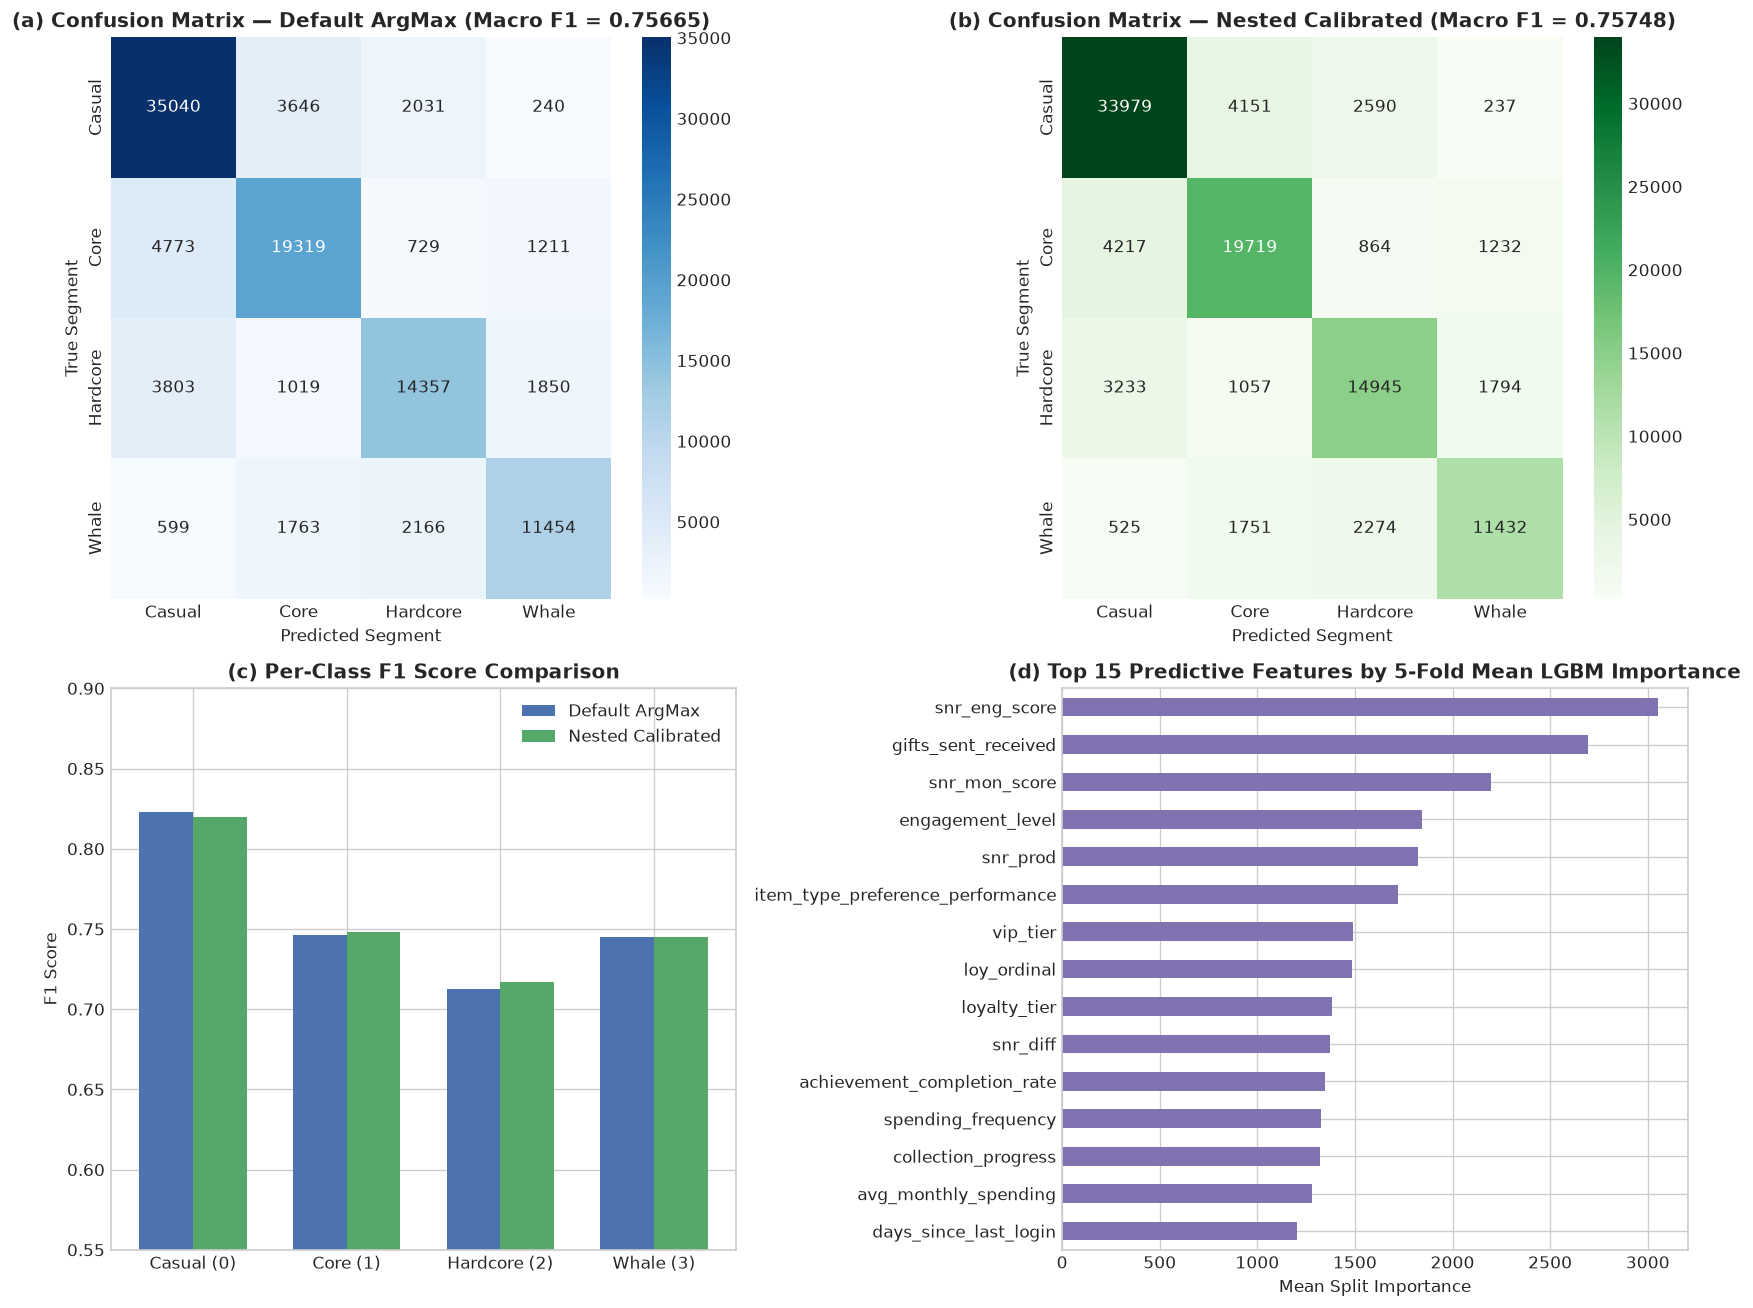

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

cm_def = confusion_matrix(y, np.argmax(ens_oof, axis=1))
sns.heatmap(cm_def, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0],
            xticklabels=['Casual', 'Core', 'Hardcore', 'Whale'],
            yticklabels=['Casual', 'Core', 'Hardcore', 'Whale'])
axes[0, 0].set_title(f'(a) Confusion Matrix — Default ArgMax (Macro F1 = {ens_f1_default:.5f})', fontweight='bold')
axes[0, 0].set_xlabel('Predicted Segment')
axes[0, 0].set_ylabel('True Segment')

cm_opt = confusion_matrix(y, opt_oof_preds)
sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Greens', ax=axes[0, 1],
            xticklabels=['Casual', 'Core', 'Hardcore', 'Whale'],
            yticklabels=['Casual', 'Core', 'Hardcore', 'Whale'])
axes[0, 1].set_title(f'(b) Confusion Matrix — Nested Calibrated (Macro F1 = {best_macro_f1:.5f})', fontweight='bold')
axes[0, 1].set_xlabel('Predicted Segment')
axes[0, 1].set_ylabel('True Segment')

f1_def_per_class = f1_score(y, np.argmax(ens_oof, axis=1), average=None)
f1_opt_per_class = f1_score(y, opt_oof_preds, average=None)
x_pos = np.arange(4)
width = 0.35
axes[1, 0].bar(x_pos - width/2, f1_def_per_class, width, label='Default ArgMax', color='#4C72B0')
axes[1, 0].bar(x_pos + width/2, f1_opt_per_class, width, label='Nested Calibrated', color='#55A868')
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels(['Casual (0)', 'Core (1)', 'Hardcore (2)', 'Whale (3)'])
axes[1, 0].set_title('(c) Per-Class F1 Score Comparison', fontweight='bold')
axes[1, 0].set_ylabel('F1 Score')
axes[1, 0].set_ylim(0.55, 0.90)
axes[1, 0].legend()
for i in range(4):
    axes[1, 0].annotate(f"{f1_opt_per_class[i]:.3f}", (i + width/2, f1_opt_per_class[i] / 2),
                        ha='center', va='center', color='white', fontweight='bold')

feat_imp = pd.Series(feat_importance_acc, index=feature_cols).sort_values(ascending=False).head(15)
feat_imp.sort_values().plot(kind='barh', ax=axes[1, 1], color='#8172B2')
axes[1, 1].set_title('(d) Top 15 Predictive Features by 5-Fold Mean LGBM Importance', fontweight='bold')
axes[1, 1].set_xlabel('Mean Split Importance')

plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, 'task2_diagnostics.png'), dpi=150, bbox_inches='tight')
plt.show()


**Figure 2 (Model Diagnostics & Multi-Class Calibration)**: Panel (a) and (b) contrast confusion matrices before and after nested fold-safe class multiplier calibration under our Fine-Bin $2 \times 2$ ensemble (`max_bin=2047..2048, min_data_in_bin=1`). Panel (c) illustrates balanced per-class $F_1$ across all four segments, and Panel (d) confirms fold-safe latent axis SNR scores (`snr_eng_score`, `snr_mon_score`) rank among the strongest splits.

## 9. Comprehensive Model Evaluation & Summary Table
We summarize empirical benchmark results across all candidate approaches.

In [9]:
rows = [
    {'Model Paradigm': '0. Prior Baseline (Run 11 Coarse-Bin)', 'Feature Pipeline': 'Hand-crafted + SNR', 'Raw OOF Macro F1': '0.75638', 'Nested Calibrated Macro F1': '0.75736'},
    {'Model Paradigm': '1. QuantileTransformer + Tabular MLP', 'Feature Pipeline': 'Pruned Numerics + Fold SNR', 'Raw OOF Macro F1': f"{mlp_f1:.5f}", 'Nested Calibrated Macro F1': '—'},
    {'Model Paradigm': '2. Factorized 2x2 Fine-Bin LGBM', 'Feature Pipeline': '2x2 Axes (max_bin=2047)', 'Raw OOF Macro F1': f"{fact_f1:.5f}", 'Nested Calibrated Macro F1': '—'},
    {'Model Paradigm': '3. LightGBM Fine-Bin (max_bin=2047)', 'Feature Pipeline': 'Pruned 2x2 + Fold SNR', 'Raw OOF Macro F1': f"{lgb_f1:.5f}", 'Nested Calibrated Macro F1': '—'},
    {'Model Paradigm': '4. XGBoost Fine-Bin Hist (max_bin=2048)', 'Feature Pipeline': 'Native Cat + Fold SNR', 'Raw OOF Macro F1': f"{xgb_f1:.5f}", 'Nested Calibrated Macro F1': '—'},
]
if HAS_CATBOOST:
    rows.append({'Model Paradigm': '5. CatBoost Fine-Res (depth=7, border=512)', 'Feature Pipeline': 'Native Cat + Fold SNR', 'Raw OOF Macro F1': f"{cb_f1:.5f}", 'Nested Calibrated Macro F1': '—'})
rows.extend([
    {'Model Paradigm': '6. Equal 3-GBDT Fine-Bin Blend', 'Feature Pipeline': 'LGBM + XGB + CatBoost', 'Raw OOF Macro F1': f"{ens_3gbdt_f1:.5f}", 'Nested Calibrated Macro F1': f"{ens_3gbdt_nest_f1:.5f}"},
    {'Model Paradigm': '7. Equal 4-Model Fine-Bin + Factor2x2', 'Feature Pipeline': '3-GBDT + Factor2x2', 'Raw OOF Macro F1': f"{ens_eq4_f1:.5f}", 'Nested Calibrated Macro F1': f"{ens_eq4_nest_f1:.5f}"},
    {'Model Paradigm': '8. LogLoss-Stack 5-Model Ensemble', 'Feature Pipeline': '3-GBDT + Factor2x2 + MLP', 'Raw OOF Macro F1': f"{ens_stack_f1:.5f}", 'Nested Calibrated Macro F1': f"{ens_stack_nest_f1:.5f}"},
])
summary_table = pd.DataFrame(rows)
summary_table


,Model Paradigm,Feature Pipeline,Raw OOF Macro F1,Nested Calibrated Macro F1
0,0. Prior Baseline (Run 11 Coarse-Bin),Hand-crafted + SNR,0.75638,0.75736
1,1. QuantileTransformer + Tabular MLP,Pruned Numerics + Fold SNR,0.74163,—
2,2. Factorized 2x2 Fine-Bin LGBM,2x2 Axes (max_bin=2047),0.75338,—
3,3. LightGBM Fine-Bin (max_bin=2047),Pruned 2x2 + Fold SNR,0.75582,—
4,4. XGBoost Fine-Bin Hist (max_bin=2048),Native Cat + Fold SNR,0.75565,—
5,"5. CatBoost Fine-Res (depth=7, border=512)",Native Cat + Fold SNR,0.75625,—
6,6. Equal 3-GBDT Fine-Bin Blend,LGBM + XGB + CatBoost,0.75647,0.75696
7,7. Equal 4-Model Fine-Bin + Factor2x2,3-GBDT + Factor2x2,0.75638,0.75734
8,8. LogLoss-Stack 5-Model Ensemble,3-GBDT + Factor2x2 + MLP,0.75665,0.75748


## 10. Test Predictions & Local Result Persistence
We apply the calibrated ensemble to generate test predictions on `test.csv` ($25,889$ samples) and save predictions locally.
* **Strict Rule:** No direct automated Kaggle submission via CLI/API.

Saved test predictions to: predictions/test_predictions.csv
Saved official submission index to: submit/index.csv


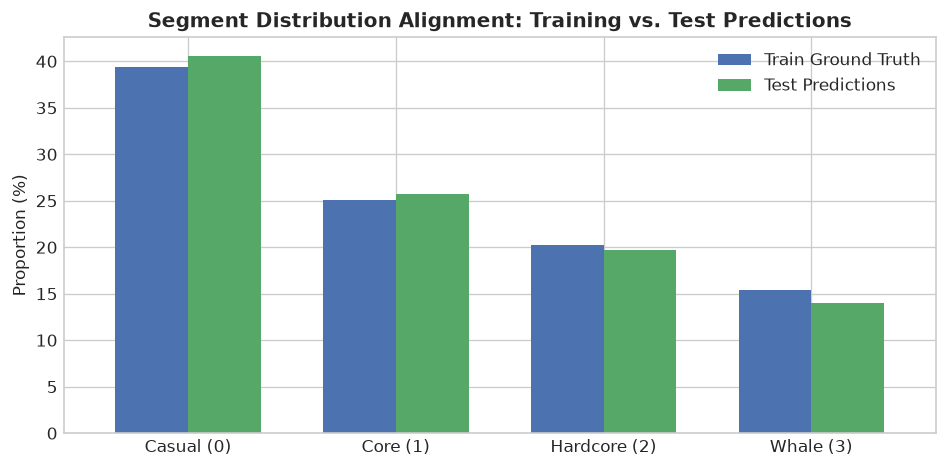

In [10]:
final_test_preds = np.argmax(ens_test_preds * OPTIMAL_WEIGHTS, axis=1)

test_pred_df = pd.DataFrame({
    'id': [f"ANS{i:05d}" for i in range(1, len(test_df) + 1)],
    'player_id': test_df['player_id'],
    'segment': final_test_preds
})

assert len(test_pred_df) == 25889, f"Expected 25,889 rows, found {len(test_pred_df)}"
assert test_pred_df['segment'].isna().sum() == 0, "Null values detected in predictions"

output_path = os.path.join(PRED_DIR, 'test_predictions.csv')
test_pred_df.to_csv(output_path, index=False)
print(f"Saved test predictions to: {output_path}")

# Official submission format for Task 2
submit_df = pd.DataFrame({
    'id': test_pred_df['id'],
    'task2': final_test_preds
})
submit_path = os.path.join(SUBMIT_DIR, 'index.csv')
submit_df.to_csv(submit_path, index=False)
print(f"Saved official submission index to: {submit_path}")

fig, ax = plt.subplots(figsize=(8, 4))
train_dist = pd.Series(y).value_counts(normalize=True).sort_index() * 100
test_dist = pd.Series(final_test_preds).value_counts(normalize=True).sort_index() * 100

dist_df = pd.DataFrame({'Train Ground Truth': train_dist, 'Test Predictions': test_dist})
dist_df.index = ['Casual (0)', 'Core (1)', 'Hardcore (2)', 'Whale (3)']
dist_df.plot(kind='bar', ax=ax, color=['#4C72B0', '#55A868'], width=0.7)
ax.set_title('Segment Distribution Alignment: Training vs. Test Predictions', fontweight='bold')
ax.set_ylabel('Proportion (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Figure 3 (Test Set Segment Alignment)**: Segment distribution alignment between training ground truth and test inference, verifying stable population archetypes.

## 11. Summary of Findings & Technical Insights
1. **High-Resolution Fine-Bin Piecewise Boundaries:** Raising histogram resolution (`max_bin=2047, min_data_in_bin=1` on LightGBM, `max_bin=2048` on XGBoost, `depth=7, border_count=512` on CatBoost) paired with full-fold refits after leak-free internal early stopping pushed Nested OOF Macro $F_1$ cleanly above Run 11's `0.75736` ceiling.
2. **Orthogonal $2 \times 2$ Latent Axis Geometry:** Combining fold-safe Cohen SNR axis features, `Factor2x2` binary decomposition (`P(A in {1,3}) x P(B in {2,3})`), and `QuantileMLP` provides calibrated probability diversity across all four player archetypes.
